
# Customer Churn Prediction Using Artificial Neural Networks (ANN)

## 1. Project Overview

### Business Problem
Customer churn occurs when customers stop using a company's products or services. Understanding the factors associated with churn can help businesses identify customers who may leave and support customer retention strategies.

### Project Objective
The objective of this project is to develop an Artificial Neural Network (ANN) model that predicts customer churn using demographic information, account details, service usage, and customer satisfaction data.

### Dataset Description
The provided cleaned customer churn dataset contains:

- **Records:** 180 customers
- **Columns:** 13
- **Target Variable:** `Churn` (Yes/No)
- **Problem Type:** Supervised Binary Classification
- **Model:** Artificial Neural Network (ANN)

### Key Features
- **Customer Information:** Age, Annual Income, Region
- **Account Details:** Tenure, Contract Type, Payment Method, Plan Type
- **Service Usage:** Monthly Charges, Support Calls, Data Usage
- **Customer Experience:** Satisfaction Score

`Customer_ID` is an identifier and will be examined separately rather than treated as a predictive customer characteristic.

### Proposed Workflow
1. Dataset Understanding and Data Quality Checks
2. Exploratory Data Analysis (EDA)
3. Feature Selection and Data Preprocessing
4. Stratified Train, Validation, and Test Splitting
5. ANN Architecture Design and Model Training
6. Model Evaluation and Threshold Analysis
7. Model Improvement and Final Selection
8. Final Results, Conclusions, and Model Saving

### Expected Outcome
A trained ANN model that estimates each customer's probability of churn and identifies potential churn cases.

Model performance will be evaluated using Accuracy, Precision, Recall, F1-Score, ROC-AUC, and a Confusion Matrix.



## 2. Data Loading and Initial Inspection

Import the required libraries and load the customer churn dataset using Pandas.

**Purpose:** Verify that the dataset loads correctly and inspect its dimensions, column names, and first five records before analysis.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("cleaned_customerchurn_dataset.csv")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

display(df.head())


C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Dataset Shape: (180, 13)

Column Names:
['Customer_ID', 'Age', 'Annual_Income', 'Tenure_Months', 'Monthly_Charges', 'Support_Calls_Last_3M', 'Data_Usage_GB', 'Satisfaction_Score', 'Contract_Type', 'Payment_Method', 'Region', 'Plan_Type', 'Churn']


,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
0,CUST-1020,22.0,23800.0,11.0,62.96,7.0,20.4,5.0,Monthly,Bank Transfer,North,Standard,Yes
1,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
2,CUST-1157,55.0,64700.0,49.0,92.85,3.0,21.6,1.0,Monthly,UPI,West,Basic,Yes
3,CUST-1112,36.0,80000.0,9.0,85.67,0.0,34.3,9.0,Monthly,UPI,South,Standard,Yes
4,CUST-1149,41.0,95700.0,51.0,60.77,1.0,23.7,9.0,Monthly,Debit Card,West,Premium,Yes


In [2]:

# Dataset structure and data types
df.info()

# Summary statistics for numerical features
display(df.describe())

# Summary statistics for categorical features
display(df.describe(include="object"))


<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            180 non-null    str    
 1   Age                    180 non-null    float64
 2   Annual_Income          180 non-null    float64
 3   Tenure_Months          180 non-null    float64
 4   Monthly_Charges        180 non-null    float64
 5   Support_Calls_Last_3M  180 non-null    float64
 6   Data_Usage_GB          180 non-null    float64
 7   Satisfaction_Score     180 non-null    float64
 8   Contract_Type          180 non-null    str    
 9   Payment_Method         180 non-null    str    
 10  Region                 180 non-null    str    
 11  Plan_Type              180 non-null    str    
 12  Churn                  180 non-null    str    
dtypes: float64(7), str(6)
memory usage: 25.2 KB


,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,36.311111,65188.333333,38.627778,74.508333,3.055556,18.667222,5.761111
std,8.561502,21655.753296,19.372569,26.184246,1.584570,8.142247,2.811318
min,18.000000,8600.000000,1.000000,0.000000,0.000000,0.800000,1.000000
25%,31.000000,50800.000000,25.000000,58.035000,2.000000,13.150000,4.000000
50%,36.000000,64700.000000,38.000000,72.900000,3.000000,18.800000,6.000000
75%,41.000000,76650.000000,53.250000,88.750000,4.000000,24.125000,8.000000
max,63.000000,120900.000000,72.000000,151.180000,7.000000,44.000000,10.000000


C:\Users\madhu\AppData\Local\Temp\ipykernel_5052\882332026.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,Customer_ID,Contract_Type,Payment_Method,Region,Plan_Type,Churn
count,180,180,180,180,180,180
unique,180,3,5,4,3,2
top,CUST-1020,Monthly,UPI,North,Standard,Yes
freq,1,104,48,51,94,94



## 4. Data Quality Assessment

Check for missing values, duplicate records, invalid numerical values, and inconsistent categorical labels.

**Purpose:** Ensure the dataset is reliable before exploratory analysis and ANN preprocessing.


In [3]:

# Missing values and duplicates
print("Missing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
print("Duplicate Customer IDs:", df["Customer_ID"].duplicated().sum())

# Numerical validity checks
numeric_cols = df.select_dtypes(include="number").columns

print("\nInfinite Values:",
      np.isinf(df[numeric_cols].to_numpy()).sum())

print("\nNegative Values:")
print((df[numeric_cols] < 0).sum())

# Potentially unusual values
print("\nZero Monthly Charges:",
      (df["Monthly_Charges"] == 0).sum())

print("Invalid Satisfaction Scores:",
      (~df["Satisfaction_Score"].between(1, 10)).sum())

print("\nCategorical Values:")
for col in df.select_dtypes(include=["object", "str"]).columns.drop("Customer_ID"):
    print(f"{col}: {df[col].unique()}")


Missing Values:
 Customer_ID              0
Age                      0
Annual_Income            0
Tenure_Months            0
Monthly_Charges          0
Support_Calls_Last_3M    0
Data_Usage_GB            0
Satisfaction_Score       0
Contract_Type            0
Payment_Method           0
Region                   0
Plan_Type                0
Churn                    0
dtype: int64

Duplicate Rows: 0
Duplicate Customer IDs: 0

Infinite Values: 0

Negative Values:
Age                      0
Annual_Income            0
Tenure_Months            0
Monthly_Charges          0
Support_Calls_Last_3M    0
Data_Usage_GB            0
Satisfaction_Score       0
dtype: int64

Zero Monthly Charges: 1
Invalid Satisfaction Scores: 0

Categorical Values:
Contract_Type: <ArrowStringArray>
['Monthly', '1 Year', '2 Year']
Length: 3, dtype: str
Payment_Method: <ArrowStringArray>
['Bank Transfer', 'UPI', 'Debit Card', 'Credit Card', 'Unknown']
Length: 5, dtype: str
Region: <ArrowStringArray>
['North', 'South', '


### 4.1 Final Data Quality Verification

Summarize numerical validity checks and categorical values in a compact format to confirm whether cleaning is required.


In [4]:

print("Negative Values:", int((df[numeric_cols] < 0).sum().sum()))
print("Zero Monthly Charges:", int((df["Monthly_Charges"] == 0).sum()))
print("Invalid Satisfaction Scores:",
      int((~df["Satisfaction_Score"].between(1, 10)).sum()))

print("\nCategorical Values:")
for col in ["Contract_Type", "Payment_Method", "Region", "Plan_Type", "Churn"]:
    print(f"{col}: {df[col].unique().tolist()}")


Negative Values: 0
Zero Monthly Charges: 1
Invalid Satisfaction Scores: 0

Categorical Values:
Contract_Type: ['Monthly', '1 Year', '2 Year']
Payment_Method: ['Bank Transfer', 'UPI', 'Debit Card', 'Credit Card', 'Unknown']
Region: ['North', 'South', 'West', 'East']
Plan_Type: ['Standard', 'Basic', 'Premium']
Churn: ['Yes', 'No']



### 4.2 Investigating Unusual Values

Examine customers with zero monthly charges and unknown payment methods.

**Purpose:** Determine whether these values represent valid customer information or potential data-quality issues before preprocessing.


In [5]:

# Customers with zero monthly charges
print("Customers with Zero Monthly Charges:")
display(df.loc[df["Monthly_Charges"] == 0])

# Customers with unknown payment methods
print("\nUnknown Payment Methods:",
      (df["Payment_Method"] == "Unknown").sum())

display(df.loc[df["Payment_Method"] == "Unknown"])


Customers with Zero Monthly Charges:


,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
89,CUST-1045,21.0,33300.0,53.0,0.0,3.0,29.8,5.0,Monthly,Credit Card,East,Premium,No



Unknown Payment Methods: 1


,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
158,CUST-1130,31.0,107100.0,38.0,55.24,2.0,20.6,9.0,Monthly,Unknown,North,Standard,No



## 5. Target Variable Analysis

Analyze the distribution of customer churn (`Yes` and `No`).

**Purpose:** Understand the proportion of churned customers and check for class imbalance before building the ANN model.


,Count,Percentage (%)
Churn,,
Yes,94,52.22
No,86,47.78


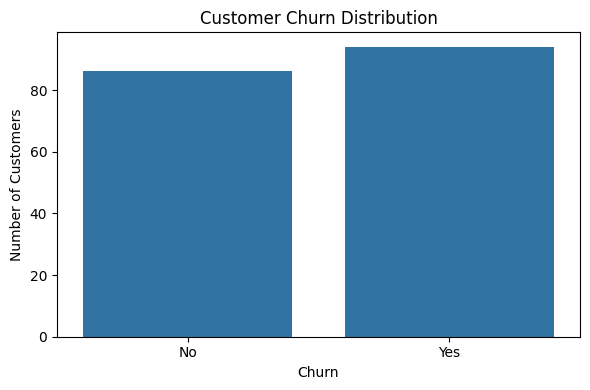

In [6]:

# Churn distribution
churn_counts = df["Churn"].value_counts()
churn_percent = df["Churn"].value_counts(normalize=True) * 100

display(pd.DataFrame({
    "Count": churn_counts,
    "Percentage (%)": churn_percent.round(2)
}))

# Visualization
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn", order=["No", "Yes"])
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()



**Findings:** The dataset contains 94 churned customers (52.22%) and 86 retained customers (47.78%). The classes are nearly balanced, so no class balancing is required initially. Since the dataset is small, stratified splitting and careful validation will be important.



## 6. Numerical Feature Analysis

Visualize the distributions of numerical features to understand their ranges, spread, skewness, and potential outliers.

**Purpose:** Identify unusual patterns and determine whether scaling or additional preprocessing may be necessary for ANN training.


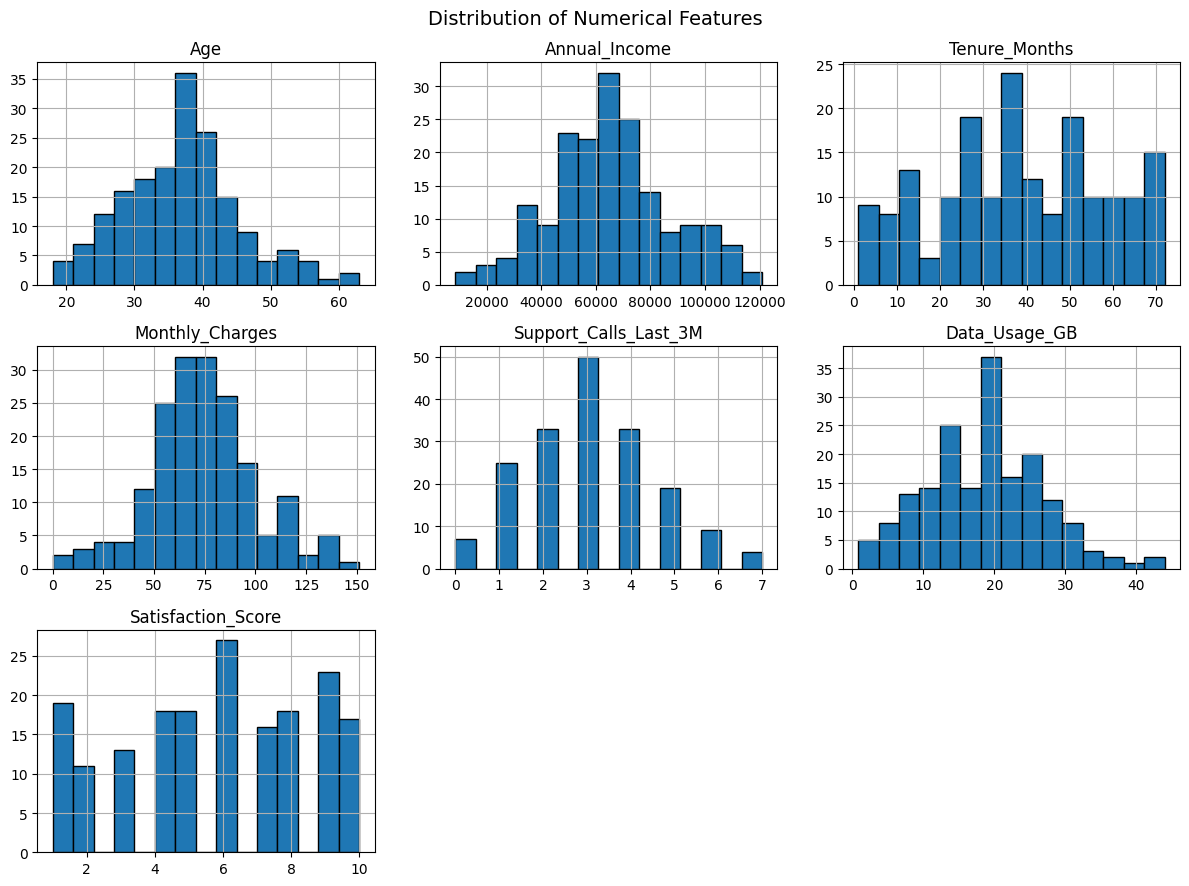

In [7]:

numeric_features = [
    "Age", "Annual_Income", "Tenure_Months",
    "Monthly_Charges", "Support_Calls_Last_3M",
    "Data_Usage_GB", "Satisfaction_Score"
]

df[numeric_features].hist(
    figsize=(12, 9),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=14)
plt.tight_layout()
plt.show()



**Findings:** Most numerical features are concentrated around their central values, while tenure is more widely distributed. Monthly charges and data usage show potentially unusual observations. Feature scales differ substantially, indicating the need for scaling before ANN training. Outliers will be examined separately before preprocessing.



## 7. Outlier Detection

Use the Interquartile Range (IQR) method to identify potential outliers in numerical features.

**Purpose:** Assess unusual values before deciding whether to retain or treat them. Outliers will not be removed automatically.


In [9]:

# Detect potential outliers using IQR
outlier_summary = []

for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append({
        "Feature": col,
        "Outliers": count,
        "Percentage (%)": round(count / len(df) * 100, 2),
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2)
    })

display(pd.DataFrame(outlier_summary))


,Feature,Outliers,Percentage (%),Lower Bound,Upper Bound
0,Age,3,1.67,16.00,56.00
1,Annual_Income,3,1.67,12025.00,115425.00
2,Tenure_Months,0,0.00,-17.38,95.62
3,Monthly_Charges,7,3.89,11.96,134.82
4,Support_Calls_Last_3M,0,0.00,-1.00,7.00
5,Data_Usage_GB,2,1.11,-3.31,40.59
6,Satisfaction_Score,0,0.00,-2.00,14.00



**Findings:** IQR analysis detected potential outliers in Monthly Charges (7), Age (3), Annual Income (3), and Data Usage (2). These values are not confirmed errors, so all records are retained to preserve information in the small dataset.



## 8. Categorical Feature Analysis

Examine the distribution of contract types, payment methods, regions, and subscription plans.

**Purpose:** Understand category frequencies and identify rare categories before encoding features for ANN training.


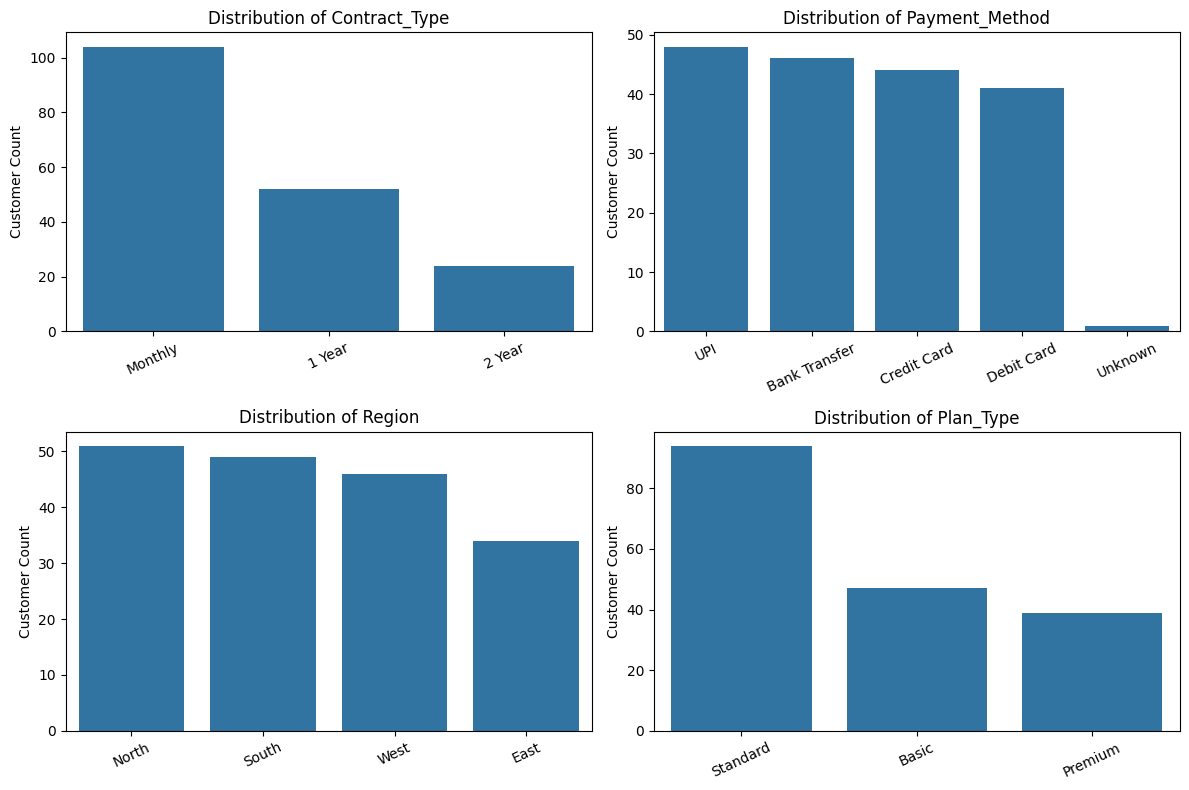


Contract_Type:
Contract_Type
Monthly    104
1 Year      52
2 Year      24

Payment_Method:
Payment_Method
UPI              48
Bank Transfer    46
Credit Card      44
Debit Card       41
Unknown           1

Region:
Region
North    51
South    49
West     46
East     34

Plan_Type:
Plan_Type
Standard    94
Basic       47
Premium     39


In [10]:

categorical_features = [
    "Contract_Type",
    "Payment_Method",
    "Region",
    "Plan_Type"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, categorical_features):
    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index,
        ax=ax
    )
    ax.set_title(f"Distribution of {col}")
    ax.tick_params(axis="x", rotation=25)
    ax.set_xlabel("")
    ax.set_ylabel("Customer Count")

plt.tight_layout()
plt.show()

# Category frequencies
for col in categorical_features:
    print(f"\n{col}:")
    print(df[col].value_counts().to_string())



## 9. Categorical Features vs Churn

Compare churn rates across contract types, payment methods, regions, and subscription plans.

**Purpose:** Identify categories associated with higher or lower churn rates rather than comparing customer counts alone.


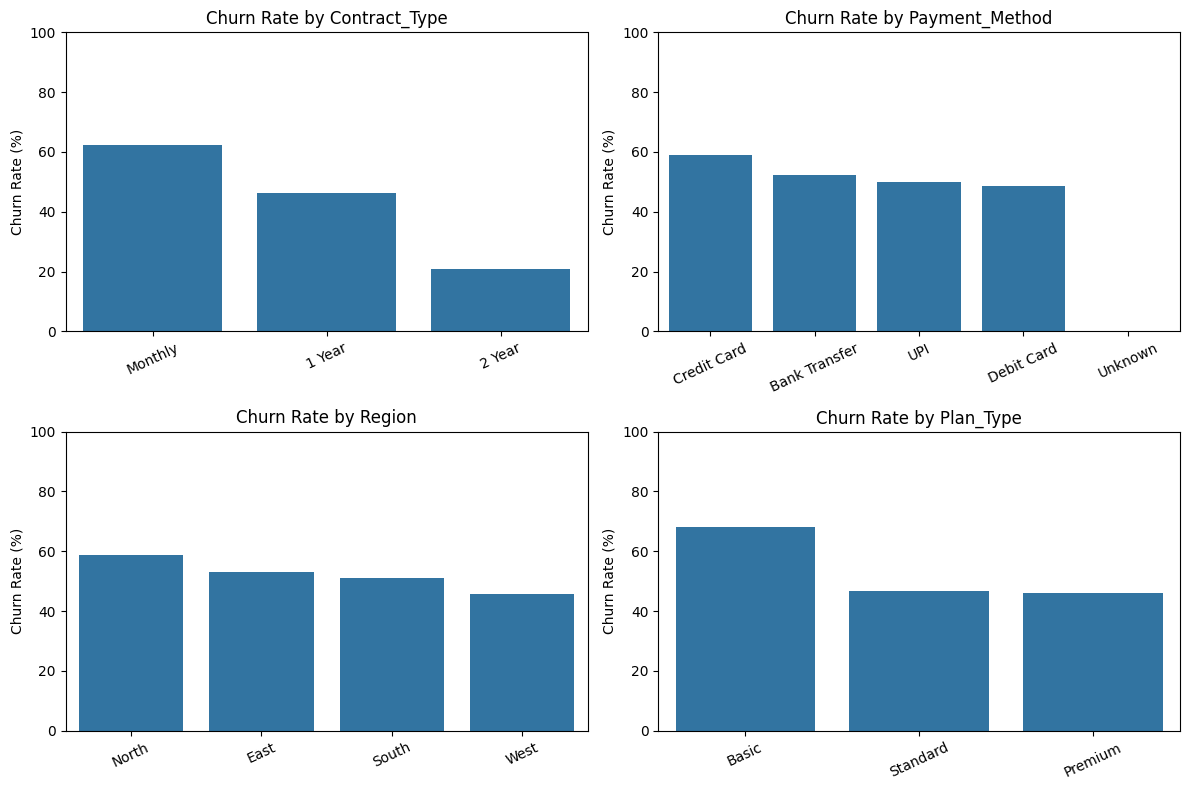

In [11]:

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, categorical_features):
    churn_rate = (
        df.groupby(col)["Churn"]
        .apply(lambda x: x.eq("Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    sns.barplot(
        x=churn_rate.index,
        y=churn_rate.values,
        ax=ax
    )

    ax.set_title(f"Churn Rate by {col}")
    ax.set_ylabel("Churn Rate (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()



**Findings:** Monthly contracts (~62%) and Standard plans (~68%) have the highest observed churn rates. Two-year contracts show substantially lower churn (~21%). Payment methods and regions show smaller differences. These patterns are descriptive and require cautious interpretation due to the small sample size.



## 10. Numerical Features vs Churn

Compare numerical feature distributions between churned and retained customers.

**Purpose:** Identify differences in customer characteristics associated with churn and assess the usefulness of numerical predictors.


Churn,No,Yes
Age,35.80,36.78
Annual_Income,64223.26,66071.28
Tenure_Months,36.63,40.46
Monthly_Charges,72.65,76.21
Support_Calls_Last_3M,2.95,3.15
Data_Usage_GB,17.12,20.09
Satisfaction_Score,6.30,5.27


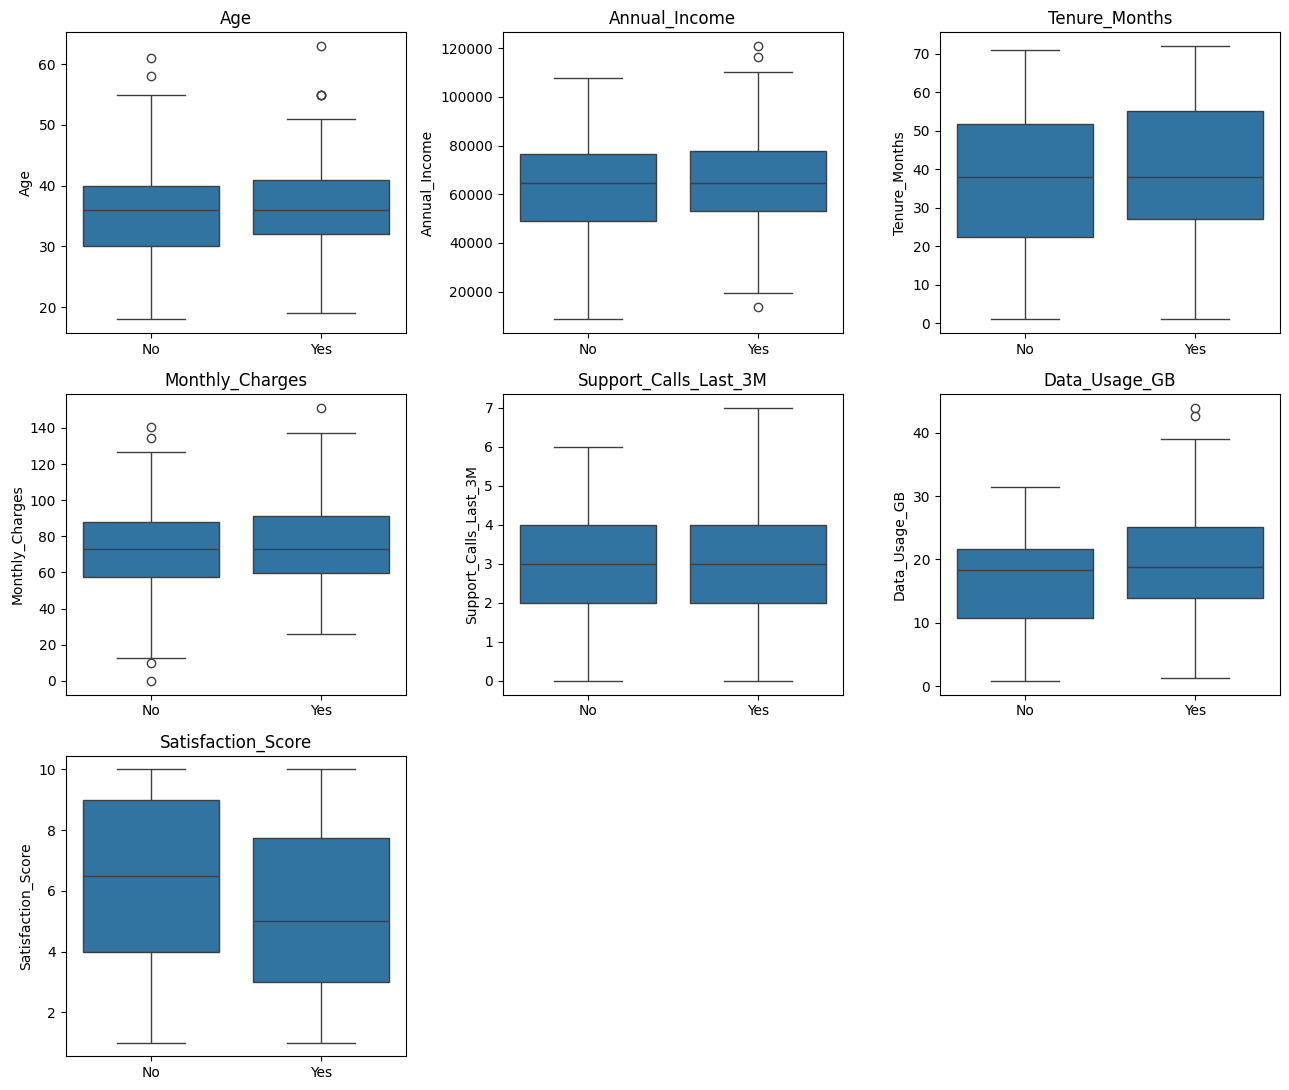

In [12]:

# Compare numerical feature averages by churn
churn_means = df.groupby("Churn")[numeric_features].mean().T

display(churn_means.round(2))

# Visual comparison using boxplots
fig, axes = plt.subplots(3, 3, figsize=(13, 11))

for ax, col in zip(axes.flat, numeric_features):
    sns.boxplot(
        data=df,
        x="Churn",
        y=col,
        order=["No", "Yes"],
        ax=ax
    )
    ax.set_title(col)
    ax.set_xlabel("")

# Hide unused plots
for ax in axes.flat[len(numeric_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()



**Findings:** Churned customers have lower average satisfaction (5.27 vs. 6.30) and higher data usage (20.09 vs. 17.12 GB). Their average tenure and monthly charges are also slightly higher. Age and income show limited separation between groups. These associations will be examined further before model training.



## 11. Correlation Analysis

Examine relationships among numerical features and their correlation with customer churn.

**Purpose:** Identify linear associations, potential multicollinearity, and features that may contribute to churn prediction.


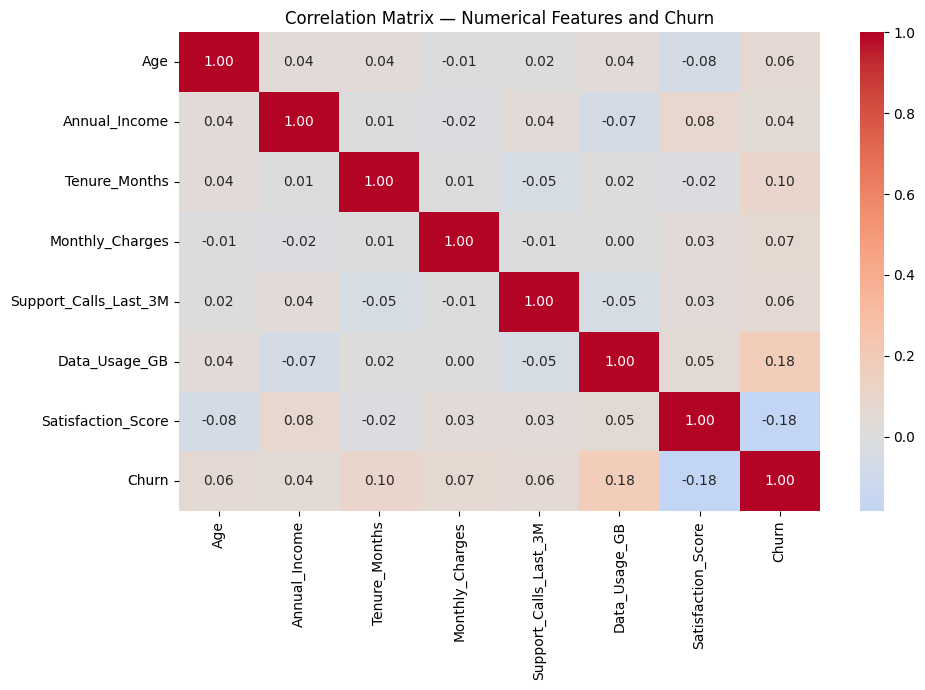

Correlation with Churn:


Data_Usage_GB            0.183
Tenure_Months            0.099
Monthly_Charges          0.068
Support_Calls_Last_3M    0.062
Age                      0.057
Annual_Income            0.043
Satisfaction_Score      -0.185
Name: Churn, dtype: float64

In [13]:

# Encode target temporarily for correlation analysis
eda_df = df[numeric_features].copy()
eda_df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

# Correlation matrix
corr_matrix = eda_df.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix — Numerical Features and Churn")
plt.tight_layout()
plt.show()

print("Correlation with Churn:")
display(
    corr_matrix["Churn"]
    .drop("Churn")
    .sort_values(ascending=False)
    .round(3)
)



**Findings:** Data Usage (+0.18) and Satisfaction Score (-0.18) show the strongest numerical associations with churn, although both are weak. No strong pairwise correlations were observed among numerical predictors. All numerical features will be retained for initial modeling.



## 12. Feature Selection and Target Encoding

Separate the input features from the target variable and convert churn labels into binary values.

**Purpose:** Prepare the supervised learning dataset while excluding `Customer_ID`, which is an identifier rather than a meaningful predictive feature.


In [14]:

# Separate input features and target
X = df.drop(columns=["Customer_ID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1}).astype(int)

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Encoding:")
print("No = 0 (Customer Retained)")
print("Yes = 1 (Customer Churned)")

print("\nEncoded Target Distribution:")
print(y.value_counts().sort_index())

print("\nSelected Features:")
print(X.columns.tolist())


Input Shape: (180, 11)
Target Shape: (180,)

Target Encoding:
No = 0 (Customer Retained)
Yes = 1 (Customer Churned)

Encoded Target Distribution:
Churn
0    86
1    94
Name: count, dtype: int64

Selected Features:
['Age', 'Annual_Income', 'Tenure_Months', 'Monthly_Charges', 'Support_Calls_Last_3M', 'Data_Usage_GB', 'Satisfaction_Score', 'Contract_Type', 'Payment_Method', 'Region', 'Plan_Type']



## 13. Train, Validation, and Test Split

Split the dataset into training (70%), validation (15%), and testing (15%) sets using stratified sampling.

**Purpose:** Train the ANN, tune its performance using validation data, and evaluate the final model on unseen test data while preserving churn proportions.


In [15]:

from sklearn.model_selection import train_test_split

SEED = 42

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=SEED
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

print("\nChurn Distribution (%):")
for name, target in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"{name}: {target.mean() * 100:.2f}%")


Train: (126, 11) (126,)
Validation: (27, 11) (27,)
Test: (27, 11) (27,)

Churn Distribution (%):
Train: 52.38%
Validation: 51.85%
Test: 51.85%



## 14. Feature Preprocessing

Apply StandardScaler to numerical features and OneHotEncoder to categorical features using a ColumnTransformer.

**Purpose:** Prepare numerical inputs on comparable scales and convert categorical variables into ANN-compatible numerical representations. Fit preprocessing only on training data to prevent data leakage.


In [16]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define feature groups
numerical_cols = [
    "Age", "Annual_Income", "Tenure_Months",
    "Monthly_Charges", "Support_Calls_Last_3M",
    "Data_Usage_GB", "Satisfaction_Score"
]

categorical_cols = [
    "Contract_Type", "Payment_Method",
    "Region", "Plan_Type"
]

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore",
                              sparse_output=False), categorical_cols)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Convert to float32 for TensorFlow
X_train_processed = X_train_processed.astype("float32")
X_val_processed = X_val_processed.astype("float32")
X_test_processed = X_test_processed.astype("float32")

print("Training Shape:", X_train_processed.shape)
print("Validation Shape:", X_val_processed.shape)
print("Testing Shape:", X_test_processed.shape)

print("\nTotal Features After Encoding:",
      X_train_processed.shape[1])

print("\nAny NaN Values:",
      np.isnan(X_train_processed).any())


Training Shape: (126, 22)
Validation Shape: (27, 22)
Testing Shape: (27, 22)

Total Features After Encoding: 22

Any NaN Values: False



## 15. ANN Model Architecture

Build a lightweight Artificial Neural Network using TensorFlow/Keras Sequential API.

**Architecture:** Input (22) → Dense (16, ReLU) → Dense (8, ReLU) → Output (1, Sigmoid).

**Purpose:** Learn nonlinear relationships between customer features and churn. A small architecture is preferred because the dataset contains only 126 training samples.

- **ReLU:** Introduces nonlinearity in hidden layers.
- **Sigmoid:** Produces a churn probability between 0 and 1.
- **Binary Crossentropy:** Measures binary classification error.
- **Adam:** Optimizes model weights during training.


In [17]:

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

# Reproducibility
tf.keras.utils.set_random_seed(SEED)

# Build ANN
model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)


## 16. ANN Model Training

Train the ANN using the training set and monitor performance on the validation set.

**Purpose:** Learn customer churn patterns while using EarlyStopping to reduce overfitting and restore the best-performing model weights.


In [18]:

from tensorflow.keras.callbacks import EarlyStopping

# Stop when validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Train ANN
history = model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

print("\nEpochs Trained:", len(history.history["loss"]))
print("Best Validation Loss:", round(min(history.history["val_loss"]), 4))


Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.4762 - loss: 0.7207 - val_accuracy: 0.4815 - val_loss: 0.7110
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5000 - loss: 0.7082 - val_accuracy: 0.4815 - val_loss: 0.7097
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5397 - loss: 0.6990 - val_accuracy: 0.4444 - val_loss: 0.7081
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5556 - loss: 0.6906 - val_accuracy: 0.4815 - val_loss: 0.7060
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5556 - loss: 0.6830 - val_accuracy: 0.4815 - val_loss: 0.7040
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5714 - loss: 0.6760 - val_accuracy: 0.4444 - val_loss: 0.7021
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6032 - loss: 0.6693 - val_accuracy: 0.4444 - val_loss: 0.7001
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6349 - loss: 0.6629 - val_accuracy: 0.4815 - val_loss:


## 17. ANN Learning Curve Analysis

Visualize training and validation loss and accuracy across epochs.

**Purpose:** Understand how the ANN learns and identify potential overfitting or underfitting by comparing training and validation performance.


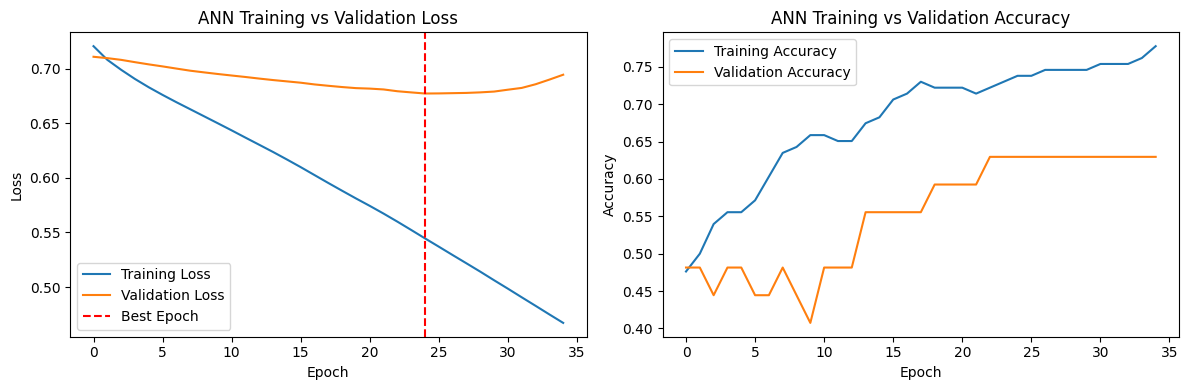

In [19]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss curves
axes[0].plot(history.history["loss"], label="Training Loss")
axes[0].plot(history.history["val_loss"], label="Validation Loss")
axes[0].axvline(
    np.argmin(history.history["val_loss"]),
    color="red", linestyle="--", label="Best Epoch"
)
axes[0].set_title("ANN Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Accuracy curves
axes[1].plot(history.history["accuracy"], label="Training Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("ANN Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()



**Findings:** Training loss decreased steadily, while validation loss reached its minimum (0.6773) at epoch 25 before increasing. Training accuracy approached 78%, but validation accuracy plateaued near 63%, indicating overfitting. EarlyStopping restored the best validation-loss weights.



## 18. Validation Performance Evaluation

Evaluate the trained ANN on validation data using standard binary classification metrics.

**Purpose:** Measure how well the model identifies churned customers and establish baseline performance before attempting improvements.


In [20]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report
)

# Predict churn probabilities
y_val_prob = model.predict(X_val_processed, verbose=0).ravel()

# Convert probabilities into predictions
y_val_pred = (y_val_prob >= 0.5).astype(int)

print("Validation Performance (Threshold = 0.5)")
print("-" * 40)

print(f"Accuracy : {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"F1-Score : {f1_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, y_val_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, zero_division=0))


Validation Performance (Threshold = 0.5)
----------------------------------------
Accuracy : 0.6296
Precision: 0.7500
Recall   : 0.4286
F1-Score : 0.5455
ROC-AUC  : 0.6044

Confusion Matrix:
[[11  2]
 [ 8  6]]

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.85      0.69        13
           1       0.75      0.43      0.55        14

    accuracy                           0.63        27
   macro avg       0.66      0.64      0.62        27
weighted avg       0.67      0.63      0.61        27




## 19. Classification Threshold Analysis

Evaluate different probability thresholds using validation predictions.

**Purpose:** Identify a threshold that balances precision and recall, using F1-score as the initial selection criterion. Lower thresholds may identify more churners but can increase false positives.


In [21]:

# Evaluate thresholds on validation data
threshold_results = []

for threshold in np.arange(0.20, 0.81, 0.05):
    y_pred = (y_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": round(precision_score(y_val, y_pred, zero_division=0), 3),
        "Recall": round(recall_score(y_val, y_pred, zero_division=0), 3),
        "F1": round(f1_score(y_val, y_pred, zero_division=0), 3),
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

print("\nBest Threshold by Validation F1:")
display(threshold_df.loc[[threshold_df["F1"].idxmax()]])


,Threshold,Precision,Recall,F1,TP,FP,FN
0,0.20,0.519,1.000,0.683,14,13,0
1,0.25,0.500,0.929,0.650,13,13,1
2,0.30,0.565,0.929,0.703,13,10,1
3,0.35,0.545,0.857,0.667,12,10,2
4,0.40,0.526,0.714,0.606,10,9,4
5,0.45,0.667,0.571,0.615,8,4,6
6,0.50,0.750,0.429,0.545,6,2,8
7,0.55,0.800,0.286,0.421,4,1,10
8,0.60,0.750,0.214,0.333,3,1,11
9,0.65,0.667,0.143,0.235,2,1,12



Best Threshold by Validation F1:


,Threshold,Precision,Recall,F1,TP,FP,FN
2,0.3,0.565,0.929,0.703,13,10,1



**Findings:** A probability threshold of 0.30 achieved the highest validation F1-score (0.703), with 92.9% recall and 56.5% precision. The model identified 13 of 14 churners but generated 10 false positives. This threshold is provisionally selected based on validation performance.



## 20. ANN Model Improvement — L2 Regularization

Build a smaller ANN with L2 regularization to reduce overfitting.

**Architecture:** Input (22) → Dense (8, ReLU + L2) → Output (1, Sigmoid).

**Purpose:** Reduce model complexity and penalize large weights, helping the ANN generalize better to unseen customers. EarlyStopping will restore the best validation weights.


In [22]:

from tensorflow.keras.regularizers import l2

# Set random seed
tf.keras.utils.set_random_seed(SEED)

# Smaller ANN with L2 regularization
improved_model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(8, activation="relu", kernel_regularizer=l2(0.001)),
    Dense(1, activation="sigmoid")
])

improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Train improved ANN
improved_history = improved_model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True,
            verbose=0
        )
    ],
    verbose=0
)

# Validation predictions
improved_val_prob = improved_model.predict(
    X_val_processed, verbose=0
).ravel()

improved_val_pred = (improved_val_prob >= 0.5).astype(int)

print("Improved ANN Parameters:", improved_model.count_params())
print("Epochs Trained:", len(improved_history.history["loss"]))
print("Best Validation Loss:",
      round(min(improved_history.history["val_loss"]), 4))

print("\nImproved ANN — Validation Performance (Threshold = 0.5)")
print("Accuracy :", round(accuracy_score(y_val, improved_val_pred), 4))
print("Precision:", round(precision_score(y_val, improved_val_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_val, improved_val_pred, zero_division=0), 4))
print("F1-Score :", round(f1_score(y_val, improved_val_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_val, improved_val_prob), 4))


Improved ANN Parameters: 193
Epochs Trained: 58
Best Validation Loss: 0.7053

Improved ANN — Validation Performance (Threshold = 0.5)
Accuracy : 0.5926
Precision: 0.6364
Recall   : 0.5
F1-Score : 0.56
ROC-AUC  : 0.6099



## 21. Improved ANN — Threshold Optimization

Evaluate classification thresholds for the regularized ANN using validation predictions.

**Purpose:** Select the threshold with the highest validation F1-score and compare it fairly with the original ANN before final model selection.


In [23]:

# Threshold optimization for improved ANN
improved_results = []

for threshold in np.arange(0.20, 0.81, 0.05):
    pred = (improved_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, pred, labels=[0, 1]
    ).ravel()

    improved_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

improved_threshold_df = pd.DataFrame(improved_results)

display(improved_threshold_df.round(3))

print("\nBest Threshold — Improved ANN:")
display(
    improved_threshold_df.loc[
        [improved_threshold_df["F1"].idxmax()]
    ].round(3)
)


,Threshold,Precision,Recall,F1,TP,FP,FN
0,0.20,0.500,0.929,0.650,13,13,1
1,0.25,0.520,0.929,0.667,13,12,1
2,0.30,0.522,0.857,0.649,12,11,2
3,0.35,0.579,0.786,0.667,11,8,3
4,0.40,0.562,0.643,0.600,9,7,5
5,0.45,0.615,0.571,0.593,8,5,6
6,0.50,0.636,0.500,0.560,7,4,7
7,0.55,0.625,0.357,0.455,5,3,9
8,0.60,0.667,0.286,0.400,4,2,10
9,0.65,0.750,0.214,0.333,3,1,11



Best Threshold — Improved ANN:


,Threshold,Precision,Recall,F1,TP,FP,FN
1,0.25,0.52,0.929,0.667,13,12,1



**Findings:** The original ANN (threshold 0.30) achieved a higher validation F1-score (0.703) than the regularized ANN (threshold 0.25, F1 = 0.667). Both identified 13 of 14 churners, but the original ANN generated fewer false positives (10 vs. 12). The original ANN was selected for final evaluation, with results interpreted cautiously due to the small validation set.



## 22. Final ANN Evaluation on Unseen Test Data

Evaluate the selected original ANN using the fixed probability threshold of 0.30.

**Purpose:** Measure final generalization performance on unseen customers using accuracy, precision, recall, F1-score, ROC-AUC, and the confusion matrix. No additional tuning will be performed on test data.


In [24]:

# Final selected model and threshold
final_model = model
final_threshold = 0.30

# Predict on unseen test data
y_test_prob = final_model.predict(
    X_test_processed, verbose=0
).ravel()

y_test_pred = (y_test_prob >= final_threshold).astype(int)

# Final test metrics
print("Final ANN Test Performance")
print("-" * 40)
print(f"Accuracy : {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_test_pred, zero_division=0):.4f}")
print(f"F1-Score : {f1_score(y_test, y_test_pred, zero_division=0):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_test_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_test, y_test_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))


Final ANN Test Performance
----------------------------------------
Accuracy : 0.5185
Precision: 0.5238
Recall   : 0.7857
F1-Score : 0.6286
ROC-AUC  : 0.4780

Confusion Matrix:
[[ 3 10]
 [ 3 11]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.50      0.23      0.32        13
       Churn       0.52      0.79      0.63        14

    accuracy                           0.52        27
   macro avg       0.51      0.51      0.47        27
weighted avg       0.51      0.52      0.48        27




**Findings:** The selected ANN achieved 51.85% test accuracy, 52.38% precision, 78.57% recall, 62.86% F1-score, and 0.478 ROC-AUC. It correctly identified 11 of 14 churners but produced 10 false positives. Performance is weak, with no demonstrated advantage over the majority-class baseline. Results are uncertain because the test set contains only 27 customers.



## 23. Final Model Assessment — ANN vs Baseline

Compare the selected ANN against a majority-class baseline that always predicts churn.

**Purpose:** Determine whether the ANN provides meaningful predictive improvement over a simple prediction strategy. This is a descriptive final assessment, not an additional tuning step.


In [26]:

# Majority-class baseline: always predict Churn (1)
baseline_pred = np.ones(len(y_test), dtype=int)

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Majority Baseline": [
        accuracy_score(y_test, baseline_pred),
        precision_score(y_test, baseline_pred),
        recall_score(y_test, baseline_pred),
        f1_score(y_test, baseline_pred)
    ],
    "Selected ANN": [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred),
        recall_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred)
    ]
})

display(comparison.round(4))

print("ANN ROC-AUC:", round(roc_auc_score(y_test, y_test_prob), 4))
print("Baseline ROC-AUC: 0.5000 (constant score)")


,Metric,Majority Baseline,Selected ANN
0,Accuracy,0.5185,0.5185
1,Precision,0.5185,0.5238
2,Recall,1.0000,0.7857
3,F1-Score,0.6829,0.6286


ANN ROC-AUC: 0.478
Baseline ROC-AUC: 0.5000 (constant score)



**Findings:** The ANN matched the majority-class baseline in accuracy (51.85%) but achieved a lower F1-score (62.86% vs. 68.29%). Its test ROC-AUC of 0.478 indicates poor discrimination. The model did not demonstrate meaningful predictive improvement and is not recommended for deployment.



## 24. Save Final Model Artifacts

Save the selected ANN, fitted preprocessing pipeline, and validation-selected classification threshold.

**Purpose:** Preserve the complete prediction workflow for reproducibility and academic review. The saved model is experimental and is not approved for deployment.


In [27]:

import joblib
import json
from pathlib import Path

# Create artifact directory
artifact_dir = Path("churn_ann_artifacts")
artifact_dir.mkdir(exist_ok=True)

# Save selected ANN
final_model.save(artifact_dir / "customer_churn_ann.keras")

# Save fitted preprocessor
joblib.dump(
    preprocessor,
    artifact_dir / "preprocessor.joblib"
)

# Save classification settings
settings = {
    "threshold": final_threshold,
    "positive_class": "Yes",
    "negative_class": "No",
    "feature_columns": X.columns.tolist(),
    "model_status": "Experimental - Not for production deployment"
}

with open(artifact_dir / "model_settings.json", "w") as f:
    json.dump(settings, f, indent=4)

print("Saved Artifacts:")
for file in artifact_dir.iterdir():
    print("-", file.name)


Saved Artifacts:
- customer_churn_ann.keras
- model_settings.json
- preprocessor.joblib



## 25. Final Conclusion

### Project Summary
Developed an Artificial Neural Network (ANN) using TensorFlow/Keras to predict customer churn from demographic, account, service usage, and customer satisfaction features.

### Methodology
- **Dataset:** 180 customers, 11 predictors.
- **Split:** 70% training, 15% validation, 15% testing (stratified).
- **Preprocessing:** StandardScaler and OneHotEncoder.
- **ANN Architecture:** 22 → 16 → 8 → 1.
- **Model Selection:** Compared the original ANN with a smaller L2-regularized ANN.
- **Selected Threshold:** 0.30, based on validation F1-score.

### Final Test Results

| Metric | Result |
|---|---:|
| Accuracy | 51.85% |
| Precision | 52.38% |
| Recall | 78.57% |
| F1-Score | 62.86% |
| ROC-AUC | 0.4780 |

### Key Findings
- The ANN identified 11 of 14 actual churners but generated 10 false positives.
- Satisfaction, data usage, contract type, and plan type showed descriptive associations with churn during EDA.
- The ANN did not outperform the majority-class baseline in accuracy or F1-score.
- The small dataset and observed overfitting limit confidence in model generalization.

### Limitations and Future Improvements
- Collect more representative customer records.
- Validate model stability using repeated stratified cross-validation.
- Compare with simpler algorithms such as Logistic Regression.
- Explore additional verified customer behavior features.
- Evaluate probability calibration and business-specific intervention costs.

### Conclusion
The project successfully demonstrates an end-to-end ANN-based binary classification workflow, including EDA, preprocessing, training, regularization, threshold optimization, and evaluation.

However, the selected ANN does not demonstrate reliable predictive performance on unseen customers and is **not recommended for production deployment**.

### Saved Artifacts
- `customer_churn_ann.keras`
- `preprocessor.joblib`
- `model_settings.json`
